In [86]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tabulate import tabulate
from scipy import stats

In [87]:
@dataclass
class PierData:
    """A slice of the 2021 pier record. """
    dnum: np.ndarray          # times, as numpy datetime64[s]
    temperature: np.ndarray   # degrees C
    pressure: np.ndarray      # decibars
    readme: str = field(
        default='2021 Pier data, SIO221a, function get_2021_pier_data.py')

    def __len__(self):
        return len(self.dnum)

def get_pier_data(file, date_start=None, date_end=None):
    """Return temperature, pressure and time from the 2020 Scripps pier record.

    Parameters
    ----------
    date_start, date_end : numpy datetime64 or str, optional
        Bracket the period you want, e.g. '2020-06-04'.  Omit both to get the
        whole record.
    file : str, optional
        Path to the netCDF file.  Omit it and we find data/scripps_pier-2020.nc
        inside the class repo.

    Returns
    -------
    pier : PierData
    """

    nc = Dataset(file)
    try:
        time = np.asarray(nc.variables['time'][:])
        temperature = np.asarray(nc.variables['temperature'][:])
        pressure = np.asarray(nc.variables['pressure'][:])
    finally:
        nc.close()

    # netCDF time is seconds since 1970-01-01, which is exactly datetime64[s].
    dnum = time.astype('datetime64[s]')

    if date_start is None:
        i1 = np.ones(dnum.shape, dtype=bool)
    else:
        i1 = ((dnum > np.datetime64(date_start)) &
              (dnum < np.datetime64(date_end)))

    return PierData(dnum=dnum[i1],
                    temperature=temperature[i1],
                    pressure=pressure[i1])


def getManyPier(numyears, start, date_start=None, date_end=None):
    """
    converts from pier object to dictionary in order to append more easily

    takes in number of years to add together, starting year

    returns: PierData object 
    
    """
    pier_data = {"dnum":np.array([], dtype='datetime64[s]'), "temperature":np.array([]), "pressure":np.array([])} #make an initial dictionary to append all the data to
    for i in range(start,start+numyears):
        pier = get_pier_data(file= "../pier_data/scripps_pier-"+str(i)+".nc")
        pier_data["dnum"] = np.concatenate((pier_data["dnum"], pier.dnum)) #preserve the order, append new values to the end
        pier_data["temperature"] = np.concatenate((pier_data["temperature"], pier.temperature))
        pier_data["pressure"] = np.concatenate((pier_data["pressure"], pier.pressure))
    pier = PierData(dnum= pier_data["dnum"], temperature=pier_data["temperature"], pressure=pier_data["pressure"])
    return pier

In [88]:
pier_2009 = get_pier_data(file = "../pier_data/scripps_pier-2009.nc")
pier_2020 = get_pier_data(file = "../pier_data/scripps_pier-2020.nc")

# Question 1

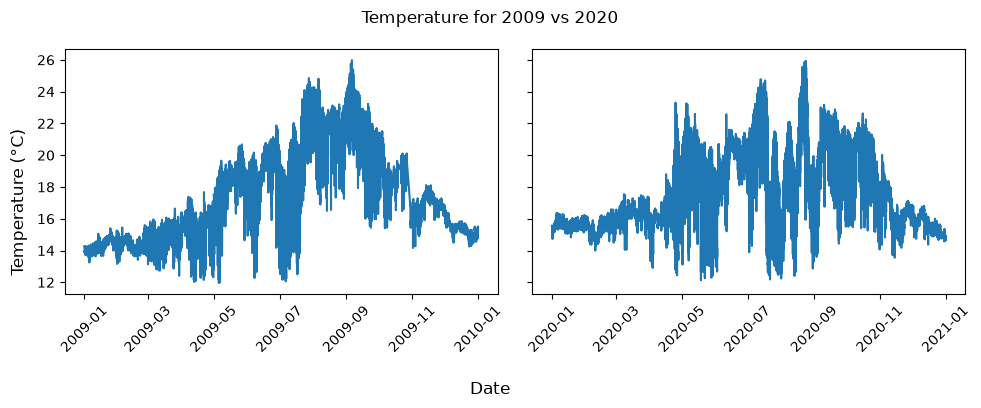

In [89]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize = (10,4))
ax1.plot(pier_2009.dnum, pier_2009.temperature)
ax1.tick_params(axis='x', rotation=45)
ax2.plot(pier_2020.dnum, pier_2020.temperature)
ax2.tick_params(axis='x', rotation=45)
fig.suptitle("Temperature for 2009 vs 2020")
fig.supylabel('Temperature (°C)')
fig.supxlabel("Date")
fig.tight_layout()

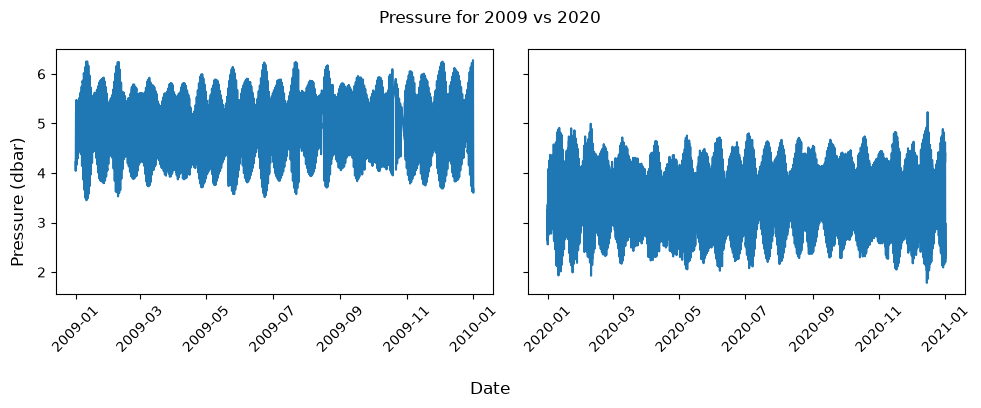

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize = (10,4))
ax1.plot(pier_2009.dnum, pier_2009.pressure)
ax1.tick_params(axis='x', rotation=45)
ax2.plot(pier_2020.dnum, pier_2020.pressure)
ax2.tick_params(axis='x', rotation=45)
fig.suptitle("Pressure for 2009 vs 2020")
fig.supylabel('Pressure (dbar)')
fig.supxlabel("Date")
fig.tight_layout()

I am comparing 2009 and 2020. The pressure graphs show noticeable visual differences in the means. Both are regular and periodic, just very different means (even from visual inspection). The temperature data looks reasonably similar. The temperatures look consistently higher in 2009 in the summer months, where 2020 has greater daily/weekly variation.

# Question 2

In [90]:
N_2009_t = len(pier_2009.temperature)
m_2009_temp =  np.mean(pier_2009.temperature)
sd_2009_temp =  np.std(pier_2009.temperature)
sem_2009_temp = sd_2009_temp/np.sqrt(N_2009_t)
sev_2009_temp = sd_2009_temp**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_temp = sev_2009_temp/(2*sd_2009_temp)

N_2009_p = len(pier_2009.pressure)
m_2009_pres =  np.mean(pier_2009.pressure)
sd_2009_pres =  np.std(pier_2009.pressure)
sem_2009_pres = sd_2009_pres/np.sqrt(N_2009_p)
sev_2009_pres = sd_2009_pres**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_pres = sev_2009_pres/(2*sd_2009_pres)

N_2020_t = len(pier_2020.temperature)
m_2020_temp =  np.mean(pier_2020.temperature)
sd_2020_temp =  np.std(pier_2020.temperature)
sem_2020_temp = sd_2020_temp/np.sqrt(N_2020_t)
sev_2020_temp = sd_2020_temp**2*np.sqrt(2/(N_2020_t-1))
sesd_2020_temp = sev_2020_temp/(2*sd_2020_temp)

N_2020_p = len(pier_2020.pressure)
m_2020_pres =  np.mean(pier_2020.pressure)
sd_2020_pres =  np.std(pier_2020.pressure)
sem_2020_pres = sd_2020_pres/np.sqrt(N_2020_p)
sev_2020_pres = sd_2020_pres**2*np.sqrt(2/(N_2020_p-1))
sesd_2020_pres = sev_2020_pres/(2*sd_2020_pres)

In [ ]:
headers = ["Statistic", "Parameter", "2009", "2020"]
stat_data = [["Mean", "Temperature", m_2009_temp, m_2020_temp], ["Standard Error of Mean", "Temperature", sem_2009_temp, sem_2020_temp], ["Mean", "Pressure", np.mean(pier_2009.pressure), np.mean(pier_2020.pressure)], ["Standard Error of Mean", "Pressure", sem_2009_pres, sem_2020_pres]]

print(tabulate(stat_data, headers = headers, tablefmt = "fancy_grid"))

#STANDARD SAMPLING


╒════════════════════════╤═════════════╤════════════╤════════════╕
│ Statistic              │ Parameter   │       2009 │       2020 │
╞════════════════════════╪═════════════╪════════════╪════════════╡
│ Mean                   │ Temperature │ 17.6343    │ 17.5947    │
├────────────────────────┼─────────────┼────────────┼────────────┤
│ Standard Error of Mean │ Temperature │  0.220398  │  0.120964  │
├────────────────────────┼─────────────┼────────────┼────────────┤
│ Mean                   │ Pressure    │  4.91091   │  3.46493   │
├────────────────────────┼─────────────┼────────────┼────────────┤
│ Standard Error of Mean │ Pressure    │  0.0363995 │  0.0259034 │
╘════════════════════════╧═════════════╧════════════╧════════════╛


In [92]:
N_2009_t = len(range(0, len(pier_2009.temperature), 360))
m_2009_temp =  np.mean(pier_2009.temperature[0::360])
sd_2009_temp =  np.std(pier_2009.temperature[0::360])
sem_2009_temp = sd_2009_temp/np.sqrt(N_2009_t)
sev_2009_temp = sd_2009_temp**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_temp = sev_2009_temp/(2*sd_2009_temp)

N_2009_p = len(range(0, len(pier_2009.pressure),360))
m_2009_pres =  np.mean(pier_2009.pressure[0::360])
sd_2009_pres =  np.std(pier_2009.pressure[0::360])
sem_2009_pres = sd_2009_pres/np.sqrt(N_2009_p)
sev_2009_pres = sd_2009_pres**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_pres = sev_2009_pres/(2*sd_2009_pres)

N_2020_t = len(range(0, len(pier_2020.temperature), 360))
m_2020_temp =  np.mean(pier_2020.temperature[0::360])
sd_2020_temp =  np.std(pier_2020.temperature[0::360])
sem_2020_temp = sd_2020_temp/np.sqrt(N_2020_t)
sev_2020_temp = sd_2020_temp**2*np.sqrt(2/(N_2020_t-1))
sesd_2020_temp = sev_2020_temp/(2*sd_2020_temp)

N_2020_p = len(range(0, len(pier_2020.pressure), 360))
m_2020_pres =  np.mean(pier_2020.pressure[0::360])
sd_2020_pres =  np.std(pier_2020.pressure[0::360])
sem_2020_pres = sd_2020_pres/np.sqrt(N_2020_p)
sev_2020_pres = sd_2020_pres**2*np.sqrt(2/(N_2020_p-1))
sesd_2020_pres = sev_2020_pres/(2*sd_2020_pres)

In [ ]:
headers = ["Statistic", "Parameter", "2009", "2020"]
stat_data = [["Mean", "Temperature", m_2009_temp, m_2020_temp], ["Standard Error of Mean", "Temperature", sem_2009_temp, sem_2020_temp], ["Mean", "Pressure", np.mean(pier_2009.pressure), np.mean(pier_2020.pressure)], ["Standard Error of Mean", "Pressure", sem_2009_pres, sem_2020_pres]]

print(tabulate(stat_data, headers = headers, tablefmt = "fancy_grid"))

#ONCE DAILY SAMPLING

╒════════════════════════╤═════════════╤════════════╤════════════╕
│ Statistic              │ Parameter   │       2009 │       2020 │
╞════════════════════════╪═════════════╪════════════╪════════════╡
│ Mean                   │ Temperature │ 17.6343    │ 17.5947    │
├────────────────────────┼─────────────┼────────────┼────────────┤
│ Standard Error of Mean │ Temperature │  0.220398  │  0.120964  │
├────────────────────────┼─────────────┼────────────┼────────────┤
│ Mean                   │ Pressure    │  4.91091   │  3.46493   │
├────────────────────────┼─────────────┼────────────┼────────────┤
│ Standard Error of Mean │ Pressure    │  0.0363995 │  0.0259034 │
╘════════════════════════╧═════════════╧════════════╧════════════╛


The means of the temperature nor the means of the pressure are within error bars of each other when using all of the data. The means of the temperature are within error bars of each other, but the pressure means are not under the subsampling once a day regime. One factor I notice is that the error bars get much larger with smaller sample sizes.

# Question 3

In [94]:
N_2009_t = len(pier_2009.temperature)
m_2009_temp =  np.mean(pier_2009.temperature)
sd_2009_temp =  np.std(pier_2009.temperature)
sem_2009_temp = sd_2009_temp/np.sqrt(N_2009_t)
sev_2009_temp = sd_2009_temp**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_temp = sev_2009_temp/(2*sd_2009_temp)

N_2009_p = len(pier_2009.pressure)
m_2009_pres =  np.mean(pier_2009.pressure)
sd_2009_pres =  np.std(pier_2009.pressure)
sem_2009_pres = sd_2009_pres/np.sqrt(N_2009_p)
sev_2009_pres = sd_2009_pres**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_pres = sev_2009_pres/(2*sd_2009_pres)

N_2020_t = len(pier_2020.temperature)
m_2020_temp =  np.mean(pier_2020.temperature)
sd_2020_temp =  np.std(pier_2020.temperature)
sem_2020_temp = sd_2020_temp/np.sqrt(N_2020_t)
sev_2020_temp = sd_2020_temp**2*np.sqrt(2/(N_2020_t-1))
sesd_2020_temp = sev_2020_temp/(2*sd_2020_temp)

N_2020_p = len(pier_2020.pressure)
m_2020_pres =  np.mean(pier_2020.pressure)
sd_2020_pres =  np.std(pier_2020.pressure)
sem_2020_pres = sd_2020_pres/np.sqrt(N_2020_p)
sev_2020_pres = sd_2020_pres**2*np.sqrt(2/(N_2020_p-1))
sesd_2020_pres = sev_2020_pres/(2*sd_2020_pres)

In [ ]:
headers = ["Statistic", "Parameter", "2009", "2020"]
stat_data = [["Variance", "Temperature", sd_2009_temp**2, sd_2020_temp**2], ["Standard Error", "Temperature", sev_2009_temp, sev_2020_temp], ["Variance", "Pressure", sd_2009_pres**2, sd_2020_pres**2], ["Standard Error", "Pressure", sev_2009_pres, sev_2020_pres]]

print(tabulate(stat_data, headers = headers, tablefmt = "fancy_grid"))

#STANDARD SAMPLING

╒════════════════╤═════════════╤════════════╤═════════════╕
│ Statistic      │ Parameter   │       2009 │        2020 │
╞════════════════╪═════════════╪════════════╪═════════════╡
│ Variance       │ Temperature │ 8.80389    │ 6.5122      │
├────────────────┼─────────────┼────────────┼─────────────┤
│ Standard Error │ Temperature │ 0.0495351  │ 0.0254997   │
├────────────────┼─────────────┼────────────┼─────────────┤
│ Variance       │ Pressure    │ 0.254666   │ 0.253336    │
├────────────────┼─────────────┼────────────┼─────────────┤
│ Standard Error │ Pressure    │ 0.00143288 │ 0.000991982 │
╘════════════════╧═════════════╧════════════╧═════════════╛


In [190]:
N_2009_t = len(range(0, len(pier_2009.temperature), 360))
m_2009_temp =  np.mean(pier_2009.temperature[0::360])
sd_2009_temp =  np.std(pier_2009.temperature[0::360])
sem_2009_temp = sd_2009_temp/np.sqrt(N_2009_t)
sev_2009_temp = sd_2009_temp**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_temp = sev_2009_temp/(2*sd_2009_temp)

N_2009_p = len(range(0, len(pier_2009.pressure),360))
m_2009_pres =  np.mean(pier_2009.pressure[0::360])
sd_2009_pres =  np.std(pier_2009.pressure[0::360])
sem_2009_pres = sd_2009_pres/np.sqrt(N_2009_p)
sev_2009_pres = sd_2009_pres**2*np.sqrt(2/(N_2009_t-1))
sesd_2009_pres = sev_2009_pres/(2*sd_2009_pres)

N_2020_t = len(range(0, len(pier_2020.temperature), 360))
m_2020_temp =  np.mean(pier_2020.temperature[0::360])
sd_2020_temp =  np.std(pier_2020.temperature[0::360])
sem_2020_temp = sd_2020_temp/np.sqrt(N_2020_t)
sev_2020_temp = sd_2020_temp**2*np.sqrt(2/(N_2020_t-1))
sesd_2020_temp = sev_2020_temp/(2*sd_2020_temp)

N_2020_p = len(range(0, len(pier_2020.pressure), 360))
m_2020_pres =  np.mean(pier_2020.pressure[0::360])
sd_2020_pres =  np.std(pier_2020.pressure[0::360])
sem_2020_pres = sd_2020_pres/np.sqrt(N_2020_p)
sev_2020_pres = sd_2020_pres**2*np.sqrt(2/(N_2020_p-1))
sesd_2020_pres = sev_2020_pres/(2*sd_2020_pres)

In [ ]:
headers = ["Statistic", "Parameter", "2009", "2020"]
stat_data = [["Variance", "Temperature", sd_2009_temp**2, sd_2020_temp**2], ["Standard Error", "Temperature", sev_2009_temp, sev_2020_temp], ["Variance", "Pressure", sd_2009_pres**2, sd_2020_pres**2], ["Standard Error", "Pressure", sev_2009_pres, sev_2020_pres]]

print(tabulate(stat_data, headers = headers, tablefmt = "fancy_grid"))
#ONCE DAILY SAMPLING

╒════════════════╤═════════════╤═══════════╤═══════════╕
│ Statistic      │ Parameter   │      2009 │      2020 │
╞════════════════╪═════════════╪═══════════╪═══════════╡
│ Variance       │ Temperature │ 8.54923   │ 5.31153   │
├────────────────┼─────────────┼───────────┼───────────┤
│ Standard Error │ Temperature │ 0.913951  │ 0.394803  │
├────────────────┼─────────────┼───────────┼───────────┤
│ Variance       │ Pressure    │ 0.233186  │ 0.243569  │
├────────────────┼─────────────┼───────────┼───────────┤
│ Standard Error │ Pressure    │ 0.0249287 │ 0.0181043 │
╘════════════════╧═════════════╧═══════════╧═══════════╛


The variances of the pressure are within error bars of each other, but the temperatures are not within error bars of each other. This is the case for both the standard data as well as the once daily sampling regime. Once again, the error bars are larger with smaller sample sizes.

# Question 4


In [97]:

m_2009_temp =  np.mean(pier_2009.temperature)
sd_2009_temp =  np.std(pier_2009.temperature)

m_2009_pres =  np.mean(pier_2009.pressure)
sd_2009_pres =  np.std(pier_2009.pressure)

m_2020_temp =  np.mean(pier_2020.temperature)
sd_2020_temp =  np.std(pier_2020.temperature)

m_2020_pres =  np.mean(pier_2020.pressure)
sd_2020_pres =  np.std(pier_2020.pressure)

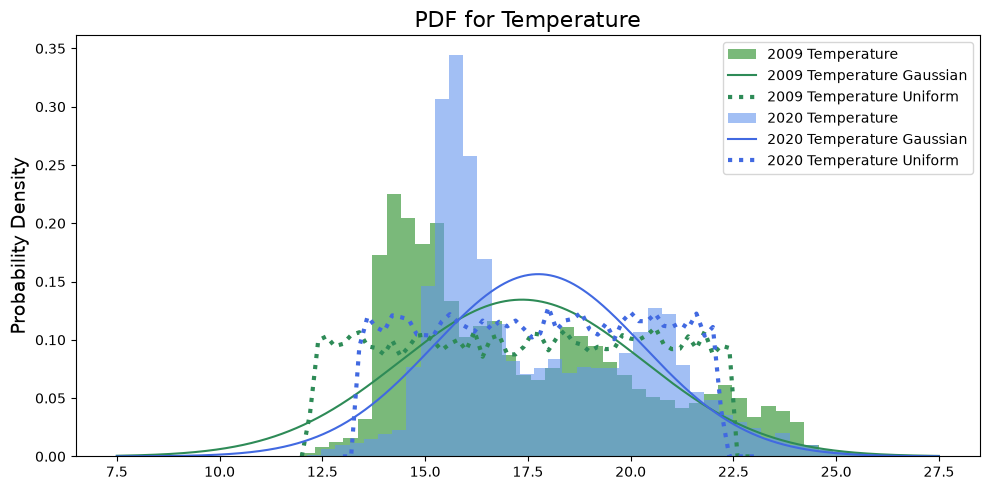

In [135]:
r = np.random.uniform(-0.5, 0.5, 10000) #altered from in class lecture 2
data_2009 = r / np.std(r, ddof=1) * sd_2009_temp + m_2009_temp
bin_size = 0.2
min_val = np.floor(data_2009.min())
max_val = np.ceil(data_2009.max())
bins = np.arange(min_val, max_val + bin_size, bin_size)
edges = np.append(bins - bin_size/2, bins[-1] + bin_size/2)
number_per_bin, _ = np.histogram(data_2009, bins=edges)

plt.figure(figsize = (10,5))



x = np.arange(7.5, 27.5, 0.001)

#plot normal distribution with mean 0 and standard deviation 1


pdf_2009 = plt.hist(pier_2009.temperature, bins=40, density=True, color = "forestgreen", alpha = 0.6, label = "2009 Temperature")
plt.plot(x, stats.norm.pdf(x, m_2009_temp, sd_2009_temp), color = "seagreen", label = "2009 Temperature Gaussian")
plt.plot(bins, number_per_bin/number_per_bin.sum()/bin_size, linewidth=3, ls=":", color = "seagreen", label = "2009 Temperature Uniform")

data_2020 = r / np.std(r, ddof=1) * sd_2020_temp + m_2020_temp
min_val = np.floor(data_2020.min())
max_val = np.ceil(data_2020.max())
bins = np.arange(min_val, max_val + bin_size, bin_size)
edges = np.append(bins - bin_size/2, bins[-1] + bin_size/2)
number_per_bin, _ = np.histogram(data_2020, bins=edges)




pdf_2020 = plt.hist(pier_2020.temperature,  bins=40, density=True, color = "cornflowerblue", alpha = 0.6, label = "2020 Temperature")
plt.plot(x, stats.norm.pdf(x, m_2020_temp, sd_2020_temp), color = "royalblue", label = "2020 Temperature Gaussian")
plt.plot(bins, number_per_bin/number_per_bin.sum()/bin_size, ls =":", color = "royalblue", linewidth = 3, label = "2020 Temperature Uniform")

plt.ylabel('Probability Density', fontsize=14)
#plt.scatter(x, ray, color = "black")
plt.title('PDF for Temperature', fontsize=16)
plt.legend()
plt.tight_layout()
plt.show()

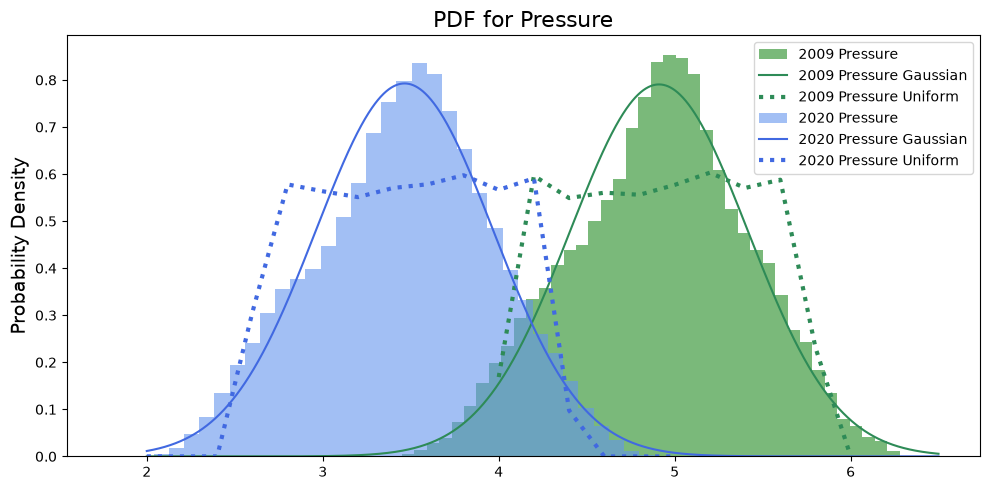

In [132]:
r = np.random.uniform(-0.5, 0.5, 10000) #altered from in class lecture 2
data_2009 = r / np.std(r, ddof=1) * sd_2009_pres + m_2009_pres
bin_size = 0.2
min_val = np.floor(data_2009.min())
max_val = np.ceil(data_2009.max())
bins = np.arange(min_val, max_val + bin_size, bin_size)
edges = np.append(bins - bin_size/2, bins[-1] + bin_size/2)
number_per_bin, _ = np.histogram(data_2009, bins=edges)

plt.figure(figsize = (10,5))
x = np.arange(2., 6.5, 0.001)
pdf = plt.hist(pier_2009.pressure, bins=40, density=True, color = "forestgreen", alpha = 0.6, label = "2009 Pressure")
plt.plot(x, stats.norm.pdf(x, m_2009_pres, sd_2009_pres), color = "seagreen", label = "2009 Pressure Gaussian")
plt.plot(bins, number_per_bin/number_per_bin.sum()/bin_size, linewidth=3, ls=":", color = "seagreen", label = "2009 Pressure Uniform")

data_2020 = r / np.std(r, ddof=1) * sd_2020_pres + m_2020_pres
min_val = np.floor(data_2020.min())
max_val = np.ceil(data_2020.max())
bins = np.arange(min_val, max_val + bin_size, bin_size)
edges = np.append(bins - bin_size/2, bins[-1] + bin_size/2)
number_per_bin, _ = np.histogram(data_2020, bins=edges)


pdf2 = plt.hist(pier_2020.pressure,  bins=40, density=True, color = "cornflowerblue", alpha = 0.6, label = "2020 Pressure")
plt.plot(x, stats.norm.pdf(x, m_2020_pres, sd_2020_pres), color = "royalblue", label = "2020 Pressure Gaussian")
plt.plot(bins, number_per_bin/number_per_bin.sum()/bin_size, ls =":", color = "royalblue", linewidth = 3, label = "2020 Pressure Uniform")

plt.ylabel('Probability Density', fontsize=14)
#plt.scatter(x, ray, color = "black")
plt.title('PDF for Pressure', fontsize=16)
plt.legend()
plt.tight_layout()
plt.show()

# Question 5

In [134]:
three_sigma_2009 = m_2009_temp+3*sd_2009_temp
print(three_sigma_2009)

26.257626


In [151]:
three_sigma_2020 = m_2020_temp+3*sd_2020_temp
print(three_sigma_2020)

25.408485


In [163]:
values, bins, _ = pdf_2009
dbin = bins[1] - bins[0]
integral = values[0:36].sum()*dbin
print(1-integral)

0.004716809187646276


In [162]:
values, bins, _ = pdf_2020
dbin = bins[1] - bins[0]
integral = values.sum()*dbin
print(1-integral)

1.9903665882115007e-07


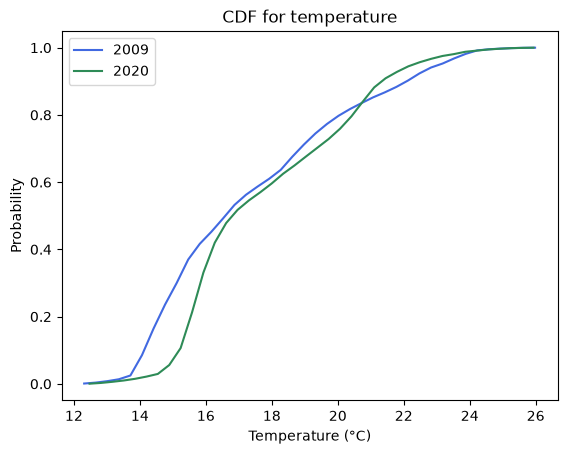

In [193]:
values1, bins1, _ = pdf_2009
values2, bins2, _ = pdf_2020

bin_width1 = np.diff(bins1)
cdf1 = np.cumsum(values1 * bin_width1)
bin_width2 = np.diff(bins2)
cdf2 = np.cumsum(values2 * bin_width2)
plt.plot(bins1[1:], cdf1, linestyle='-', color='royalblue', label='2009')
plt.plot(bins2[1:], cdf2, linestyle='-', color='seagreen', label='2020')
plt.xlabel('Temperature (°C)')
plt.ylabel('Probability')
plt.title('CDF for temperature')
plt.legend()
plt.show()

Now for the Gaussian PDF.

In [ ]:
x = np.arange(7.5, 27.5, 0.001)
gau_2009 = stats.norm.pdf(x, m_2009_temp, sd_2009_temp)
gau_2020 = stats.norm.pdf(x, m_2020_temp, sd_2020_temp)

array([0.00054013, 0.00054073, 0.00054134, ..., 0.00039097, 0.00039052,
       0.00039007], shape=(20000,))

In [ ]:
dbin = 0.001
integral = gau_2009[0:18758].sum()*dbin #got this value via searching for where the bin containing it was
print(1-integral)

0.0017970122074463246


In [180]:
dbin = 0.001
integral = gau_2020[0:17909].sum()*dbin #got this value via searching for where the bin containing it was
print(1-integral)


0.001379232787390272


The likelihood of getting a value 3$\sigma$ greater than the mean temperature for 2009 is 0.005 from the observed PDF. The likelihood of getting a value 3$\sigma$ greater than the mean temperature for 2020 is 2*10^-7 from the observed PDF. From the Gaussian PDF with the same standard deviation as the 2009 data, the likelihood of getting the value is 0.002; for 2020 that likelihood is 0.0014. The 2009 data is not far off, but the 2020 data shows significant deviation from the Gaussian expectation.